In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import gc

In [ ]:
# =========================================================
# PATHS
# =========================================================

base_path = "/content/drive/MyDrive/Colab Notebooks/modele stocastique/"

train_path = base_path + "train_ST4000DM000_cleaned.pkl"
test_path = base_path + "test_ST4000DM000_cleaned.pkl"

# =========================================================
# LOAD
# =========================================================

train_df = pd.read_pickle(train_path)
test_df = pd.read_pickle(test_path)

print("Train shape :", train_df.shape)
print("Test shape  :", test_df.shape)

Train shape : (9085357, 27)
Test shape  : (3196552, 27)


In [ ]:
train_df.head()

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-06-03,S3000A9T,0,107687208.0,0.0,33.0,0.0,33158496.0,728.0,0.0,...,0.0,2.0,1785.0,25.0,0.0,0.0,0.0,503.0,5.442997e+09,304800640.0
1,2017-06-04,S3000A9T,0,132850464.0,0.0,33.0,0.0,33315264.0,752.0,0.0,...,0.0,2.0,2337.0,25.0,0.0,0.0,0.0,525.0,9.374590e+09,319131616.0
2,2017-06-05,S3000A9T,0,176573120.0,0.0,33.0,0.0,33376638.0,776.0,0.0,...,0.0,0.0,3547.0,25.0,0.0,0.0,0.0,545.0,9.374697e+09,351515712.0
3,2017-06-06,S3000A9T,0,218899664.0,0.0,33.0,0.0,33435680.0,800.0,0.0,...,0.0,0.0,4728.0,25.0,0.0,0.0,0.0,565.0,9.374803e+09,384307744.0
4,2017-06-07,S3000A9T,0,19331576.0,0.0,33.0,0.0,33495492.0,824.0,0.0,...,0.0,0.0,5912.0,25.0,0.0,0.0,0.0,584.0,9.374907e+09,415046976.0


In [ ]:
train_df["failure"].value_counts()

,count
failure,
0,9084581
1,776


In [ ]:
# =========================================================
# DISQUES DÉFAILLANTS
# =========================================================

failed_disks = train_df[
    train_df["failure"] == 1
]["serial_number"].unique()

failed_disks = list(failed_disks)

print("Nombre de disques défaillants :", len(failed_disks))

print("\nExemples :")
print(failed_disks[:10])

Nombre de disques défaillants : 776

Exemples :
['S30070F5', 'S300CCWE', 'S300PFN5', 'S300RS9T', 'S300TQZA', 'S300VKP4', 'S300VL64', 'S300VLLF', 'S300WE57', 'S300WEE9']


In [ ]:
# =========================================================
# DATASET NORMAL
# =========================================================

normal_df = train_df[
    ~train_df["serial_number"].isin(failed_disks)
]

print("Shape normal_df :", normal_df.shape)

Shape normal_df : (8986282, 27)


In [ ]:
# =========================================================
# NOMBRE D'OBSERVATIONS PAR DISQUE
# =========================================================

disk_counts = normal_df["serial_number"].value_counts()

print(disk_counts.head(20))

serial_number
Z304JDAL    269
Z300CM2A    269
Z300CM2K    269
Z300CM3S    269
Z300CM3Z    269
Z300CM47    269
Z300CLL5    269
Z300CLLX    269
Z300CLM1    269
Z300CLN9    269
Z304KBVF    269
Z300CLQF    269
Z304JDA6    269
Z300CLRS    269
Z300CLRY    269
Z300CLSH    269
Z300CM90    269
Z300CMAE    269
Z300CMAM    269
Z300CMAS    269
Name: count, dtype: int64


In [ ]:
# =========================================================
# PARAMÈTRE
# =========================================================

MAX_NORMAL_DISKS = 50

In [ ]:
# =========================================================
# SÉLECTION DES DISQUES NORMAUX
# =========================================================

normal_disks = list(
    disk_counts.head(MAX_NORMAL_DISKS).index
)

print("Nombre de disques normaux :", len(normal_disks))

Nombre de disques normaux : 50


In [ ]:
intersection = set(failed_disks).intersection(set(normal_disks))

print("Intersection :", len(intersection))

Intersection : 0


In [ ]:
# =========================================================
# DISQUES NORMAUX SÉLECTIONNÉS
# =========================================================

selected_normal_df = train_df[
    train_df["serial_number"].isin(normal_disks)
]

# =========================================================
# DISQUES DÉFAILLANTS
# =========================================================

failed_df = train_df[
    train_df["serial_number"].isin(failed_disks)
]

print("Normal shape :", selected_normal_df.shape)
print("Failed shape :", failed_df.shape)

Normal shape : (13450, 27)
Failed shape : (99075, 27)


In [ ]:
final_selected_df = pd.concat(
    [selected_normal_df, failed_df],
    ignore_index=True
)

print(final_selected_df.shape)

(112525, 27)


In [ ]:
print("Nombre de disques normaux :",
      len(normal_disks))

print("Nombre de disques défaillants :",
      len(failed_disks))

Nombre de disques normaux : 50
Nombre de disques défaillants : 776


In [ ]:
selection_path = (
    base_path +
    "selected_disks_dataset.pkl"
)

final_selected_df.to_pickle(selection_path)

print("Dataset sauvegardé")

Dataset sauvegardé


In [ ]:
# =========================================================
# LOAD DATASET SÉLECTIONNÉ
# =========================================================

selected_path = (
    base_path +
    "selected_disks_dataset.pkl"
)

df = pd.read_pickle(selected_path)

print(df.shape)

(112525, 27)


In [ ]:
df["serial_number"].nunique()

826

In [ ]:
sample_disk = df["serial_number"].iloc[0]

sample_disk

'Z300BYE9'

In [ ]:
disk_df = df[
    df["serial_number"] == sample_disk
].copy()

print(disk_df.shape)

(269, 27)


In [ ]:
disk_df = disk_df.sort_values("date")

disk_df.head()

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-01-01,Z300BYE9,0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,...,0.0,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11
1,2017-01-02,Z300BYE9,0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
2,2017-01-03,Z300BYE9,0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
3,2017-01-04,Z300BYE9,0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
4,2017-01-05,Z300BYE9,0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11


In [ ]:
start_date = disk_df["date"].min()
end_date = disk_df["date"].max()

print("Début :", start_date)
print("Fin   :", end_date)

total_days = (end_date - start_date).days + 1

print("Nombre théorique de jours :", total_days)
print("Nombre réel de lignes     :", len(disk_df))

Début : 2017-01-01 00:00:00
Fin   : 2017-12-31 00:00:00
Nombre théorique de jours : 365
Nombre réel de lignes     : 269


In [ ]:
missing_days = total_days - len(disk_df)

print("Jours manquants :", missing_days)

Jours manquants : 96


In [ ]:
all_dates = pd.date_range(
    start=start_date,
    end=end_date,
    freq="D"
)

print("Nombre total de dates :", len(all_dates))

Nombre total de dates : 365


In [ ]:
disk_df = disk_df.set_index("date")

disk_df = disk_df.reindex(all_dates)

disk_df.head(10)

,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,smart_12_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
2017-01-01,Z300BYE9,0.0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,11.0,...,0.0,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11
2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,11.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,11.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,11.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,11.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11
2017-01-06,Z300BYE9,0.0,120290960.0,0.0,12.0,0.0,839962304.0,29186.0,0.0,11.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29148.0,3.102475e+10,1.426221e+11
2017-01-07,Z300BYE9,0.0,230604448.0,0.0,12.0,0.0,840874816.0,29211.0,0.0,11.0,...,0.0,5.0,8725.0,15.0,0.0,0.0,0.0,29173.0,3.103248e+10,1.426598e+11
2017-01-08,Z300BYE9,0.0,243951584.0,0.0,12.0,0.0,841708416.0,29234.0,0.0,11.0,...,0.0,5.0,8725.0,15.0,0.0,0.0,0.0,29197.0,3.103991e+10,1.426925e+11
2017-01-09,Z300BYE9,0.0,4170680.0,0.0,12.0,0.0,842534400.0,29258.0,0.0,11.0,...,0.0,5.0,8725.0,15.0,0.0,0.0,0.0,29220.0,3.104697e+10,1.427275e+11
2017-01-10,Z300BYE9,0.0,49502584.0,0.0,12.0,0.0,843425216.0,29283.0,0.0,11.0,...,0.0,5.0,8725.0,16.0,0.0,0.0,0.0,29245.0,3.105649e+10,1.427629e+11


In [ ]:
disk_df.index.name = "date"

disk_df = disk_df.reset_index()

disk_df.head()

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-01-01,Z300BYE9,0.0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,...,0.0,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11
1,2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
2,2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
3,2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
4,2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11


In [ ]:
disk_df.isnull().sum().sort_values(
    ascending=False
).head(20)

,0
serial_number,96
failure,96
smart_1_raw,96
smart_7_raw,96
smart_3_raw,96
smart_4_raw,96
smart_5_raw,96
smart_10_raw,96
smart_9_raw,96
smart_12_raw,96


In [ ]:
disk_df = disk_df.ffill()

disk_df.head(10)

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-01-01,Z300BYE9,0.0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,...,0.0,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11
1,2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
2,2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
3,2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
4,2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11
5,2017-01-06,Z300BYE9,0.0,120290960.0,0.0,12.0,0.0,839962304.0,29186.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29148.0,3.102475e+10,1.426221e+11
6,2017-01-07,Z300BYE9,0.0,230604448.0,0.0,12.0,0.0,840874816.0,29211.0,0.0,...,0.0,5.0,8725.0,15.0,0.0,0.0,0.0,29173.0,3.103248e+10,1.426598e+11
7,2017-01-08,Z300BYE9,0.0,243951584.0,0.0,12.0,0.0,841708416.0,29234.0,0.0,...,0.0,5.0,8725.0,15.0,0.0,0.0,0.0,29197.0,3.103991e+10,1.426925e+11
8,2017-01-09,Z300BYE9,0.0,4170680.0,0.0,12.0,0.0,842534400.0,29258.0,0.0,...,0.0,5.0,8725.0,15.0,0.0,0.0,0.0,29220.0,3.104697e+10,1.427275e+11
9,2017-01-10,Z300BYE9,0.0,49502584.0,0.0,12.0,0.0,843425216.0,29283.0,0.0,...,0.0,5.0,8725.0,16.0,0.0,0.0,0.0,29245.0,3.105649e+10,1.427629e+11


In [ ]:
print("NaN restants :")
print(disk_df.isnull().sum().sum())

NaN restants :
0


In [ ]:
new_total_days = (
    disk_df["date"].max()
    -
    disk_df["date"].min()
).days + 1

print("Jours théoriques :", new_total_days)
print("Lignes réelles   :", len(disk_df))

Jours théoriques : 365
Lignes réelles   : 365


In [ ]:
# =========================================================
# FONCTION CORRECTION TEMPORELLE
# =========================================================

def temporal_correction(disk_data):

    # TRI
    disk_data = disk_data.sort_values("date")

    # DATES
    start_date = disk_data["date"].min()
    end_date = disk_data["date"].max()

    all_dates = pd.date_range(
        start=start_date,
        end=end_date,
        freq="D"
    )

    # REINDEX
    disk_data = disk_data.set_index("date")

    disk_data = disk_data.reindex(all_dates)

    # RESTORE DATE
    disk_data.index.name = "date"

    disk_data = disk_data.reset_index()

    # FORWARD FILL
    disk_data = disk_data.ffill()

    return disk_data

In [ ]:
test_disk = temporal_correction(
    df[df["serial_number"] == sample_disk]
)

print(test_disk.shape)

test_disk.head()

(365, 27)


,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-01-01,Z300BYE9,0.0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,...,0.0,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11
1,2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
2,2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
3,2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
4,2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11


In [ ]:
all_disks = df["serial_number"].unique()

print("Nombre total de disques :", len(all_disks))

Nombre total de disques : 826


In [ ]:
# =========================================================
# CORRECTION TEMPORELLE GLOBALE
# =========================================================

corrected_disks = []

for i, disk in enumerate(all_disks):

    # EXTRACTION
    disk_data = df[
        df["serial_number"] == disk
    ].copy()

    # CORRECTION
    corrected_disk = temporal_correction(disk_data)

    # AJOUT
    corrected_disks.append(corrected_disk)

    # AFFICHAGE
    if (i + 1) % 10 == 0:
        print(f"{i+1} disques traités")

10 disques traités
20 disques traités
30 disques traités
40 disques traités
50 disques traités
60 disques traités
70 disques traités
80 disques traités
90 disques traités
100 disques traités
110 disques traités
120 disques traités
130 disques traités
140 disques traités
150 disques traités
160 disques traités
170 disques traités
180 disques traités
190 disques traités
200 disques traités
210 disques traités
220 disques traités
230 disques traités
240 disques traités
250 disques traités
260 disques traités
270 disques traités
280 disques traités
290 disques traités
300 disques traités
310 disques traités
320 disques traités
330 disques traités
340 disques traités
350 disques traités
360 disques traités
370 disques traités
380 disques traités
390 disques traités
400 disques traités
410 disques traités
420 disques traités
430 disques traités
440 disques traités
450 disques traités
460 disques traités
470 disques traités
480 disques traités
490 disques traités
500 disques traités
510 disqu

In [ ]:
corrected_df = pd.concat(
    corrected_disks,
    ignore_index=True
)

print(corrected_df.shape)

(142150, 27)


In [ ]:
corrected_df = corrected_df.reset_index(drop=True)

print("Index réinitialisés")

Index réinitialisés


In [ ]:
corrected_df.isnull().sum().sort_values(
    ascending=False
).head(20)

,0
date,0
serial_number,0
failure,0
smart_1_raw,0
smart_3_raw,0
smart_4_raw,0
smart_5_raw,0
smart_7_raw,0
smart_9_raw,0
smart_10_raw,0


In [ ]:
sample_disk = corrected_df["serial_number"].iloc[0]

check_disk = corrected_df[
    corrected_df["serial_number"] == sample_disk
]

# =========================================================
# COMPARAISON
# =========================================================

theoretical_days = (
    check_disk["date"].max()
    -
    check_disk["date"].min()
).days + 1

real_days = len(check_disk)

print("Jours théoriques :", theoretical_days)
print("Lignes réelles   :", real_days)

Jours théoriques : 365
Lignes réelles   : 365


In [ ]:
corrected_path = (
    base_path +
    "corrected_temporal_dataset.pkl"
)

corrected_df.to_pickle(corrected_path)

print("Dataset corrigé sauvegardé")

Dataset corrigé sauvegardé


In [ ]:
del corrected_disks

gc.collect()

print("Mémoire libérée")

Mémoire libérée


In [ ]:
# =========================================================
# LOAD DATASET CORRIGÉ
# =========================================================

corrected_path = (
    base_path +
    "corrected_temporal_dataset.pkl"
)

df = pd.read_pickle(corrected_path)

print(df.shape)

(142150, 27)


In [ ]:
# =========================================================
# PARAMÈTRES
# =========================================================

sequence_length = 5
lookahead_days = 2

print("sequence_length :", sequence_length)
print("lookahead_days  :", lookahead_days)

sequence_length : 5
lookahead_days  : 2


In [ ]:
failed_disks = df[
    df["failure"] == 1
]["serial_number"].unique()

failed_disks = list(failed_disks)

print("Nombre :", len(failed_disks))

Nombre : 776


In [ ]:
# =========================================================
# FONCTION SÉQUENCE DÉFAILLANTE
# =========================================================

def create_failed_sequence(disk_data,
                           sequence_length,
                           lookahead_days):

    # TRI
    disk_data = disk_data.sort_values("date")

    # POSITION PANNE
    failure_index = disk_data[
        disk_data["failure"] == 1
    ].index[0]

    # POSITION FIN SÉQUENCE
    sequence_end = failure_index - lookahead_days

    # POSITION DÉBUT
    sequence_start = (
        sequence_end - sequence_length
    )

    # EXTRACTION
    sequence = disk_data.loc[
        sequence_start:sequence_end - 1
    ]

    return sequence

In [ ]:
sample_failed_disk = failed_disks[0]

sample_failed_disk

'S30070F5'

In [ ]:
disk_data = df[
    df["serial_number"] == sample_failed_disk
].copy()

disk_data.shape

(55, 27)

In [ ]:
failed_sequence = create_failed_sequence(
    disk_data,
    sequence_length,
    lookahead_days
)

failed_sequence

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
18297,2017-02-17,S30070F5,0.0,126138464.0,0.0,8.0,0.0,530021312.0,25233.0,0.0,...,0.0,2.0,8249.0,28.0,0.0,0.0,0.0,25162.0,2.314776e+10,8.874176e+10
18298,2017-02-18,S30070F5,0.0,117121064.0,0.0,8.0,0.0,530898432.0,25257.0,0.0,...,0.0,2.0,8249.0,29.0,0.0,0.0,0.0,25186.0,2.315552e+10,8.877944e+10
18299,2017-02-19,S30070F5,0.0,83295096.0,0.0,8.0,0.0,531725600.0,25281.0,0.0,...,0.0,2.0,8249.0,30.0,0.0,0.0,0.0,25210.0,2.316110e+10,8.881304e+10
18300,2017-02-20,S30070F5,0.0,73725216.0,0.0,8.0,0.0,532565600.0,25305.0,0.0,...,0.0,2.0,8249.0,29.0,0.0,0.0,0.0,25234.0,2.316667e+10,8.884915e+10
18301,2017-02-21,S30070F5,0.0,41438696.0,0.0,8.0,0.0,533423904.0,25329.0,0.0,...,0.0,2.0,8249.0,29.0,0.0,0.0,0.0,25258.0,2.317391e+10,8.888441e+10


In [ ]:
print(len(failed_sequence))

5


In [ ]:
failed_sequences = []

In [ ]:
# =========================================================
# TOUTES LES SÉQUENCES DÉFAILLANTES
# =========================================================



for disk in failed_disks:

    disk_data = df[
        df["serial_number"] == disk
    ].copy()

    try:

        sequence = create_failed_sequence(
            disk_data,
            sequence_length,
            lookahead_days
        )

        # VÉRIFICATION TAILLE
        if len(sequence) == sequence_length:
            failed_sequences.append(sequence)

    except:
        pass

print("Nombre de séquences défaillantes :",
      len(failed_sequences))

Nombre de séquences défaillantes : 757


In [ ]:
failed_sequences_df = pd.concat(
    failed_sequences,
    ignore_index=True
)

print(failed_sequences_df.shape)

(3785, 27)


In [ ]:
failed_sequences_df.head(10)

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-02-17,S30070F5,0.0,126138464.0,0.0,8.0,0.0,530021312.0,25233.0,0.0,...,0.0,2.0,8249.0,28.0,0.0,0.0,0.0,25162.0,2.314776e+10,8.874176e+10
1,2017-02-18,S30070F5,0.0,117121064.0,0.0,8.0,0.0,530898432.0,25257.0,0.0,...,0.0,2.0,8249.0,29.0,0.0,0.0,0.0,25186.0,2.315552e+10,8.877944e+10
2,2017-02-19,S30070F5,0.0,83295096.0,0.0,8.0,0.0,531725600.0,25281.0,0.0,...,0.0,2.0,8249.0,30.0,0.0,0.0,0.0,25210.0,2.316110e+10,8.881304e+10
3,2017-02-20,S30070F5,0.0,73725216.0,0.0,8.0,0.0,532565600.0,25305.0,0.0,...,0.0,2.0,8249.0,29.0,0.0,0.0,0.0,25234.0,2.316667e+10,8.884915e+10
4,2017-02-21,S30070F5,0.0,41438696.0,0.0,8.0,0.0,533423904.0,25329.0,0.0,...,0.0,2.0,8249.0,29.0,0.0,0.0,0.0,25258.0,2.317391e+10,8.888441e+10
5,2017-03-05,S300CCWE,0.0,89061792.0,0.0,4.0,0.0,8689559.0,1971.0,0.0,...,0.0,0.0,40733.0,24.0,0.0,0.0,0.0,1822.0,7.990251e+09,1.100093e+09
6,2017-03-06,S300CCWE,0.0,53978384.0,0.0,4.0,0.0,8777109.0,1996.0,0.0,...,0.0,0.0,40733.0,26.0,0.0,0.0,0.0,1846.0,7.992870e+09,1.186321e+09
7,2017-03-07,S300CCWE,0.0,75876376.0,0.0,4.0,0.0,8926846.0,2019.0,0.0,...,0.0,0.0,40733.0,23.0,0.0,0.0,0.0,1870.0,8.014074e+09,1.276920e+09
8,2017-03-08,S300CCWE,0.0,159951296.0,0.0,4.0,0.0,9082168.0,2043.0,0.0,...,0.0,0.0,40733.0,24.0,0.0,0.0,0.0,1894.0,8.018181e+09,1.368138e+09
9,2017-03-09,S300CCWE,0.0,72599432.0,0.0,4.0,0.0,9389205.0,2067.0,0.0,...,0.0,0.0,40733.0,24.0,0.0,0.0,0.0,1918.0,8.028190e+09,1.456814e+09


In [ ]:
# =========================================================
# DISQUES NORMAUX
# =========================================================

normal_disks = df[
    df["failure"] == 0
]["serial_number"].unique()

# =========================================================
# SUPPRIMER LES DISQUES DÉFAILLANTS
# =========================================================

normal_disks = [
    disk for disk in normal_disks
    if disk not in failed_disks
]

print("Nombre de disques normaux :",
      len(normal_disks))

Nombre de disques normaux : 50


In [ ]:
# =========================================================
# FONCTION SÉQUENCES NORMALES
# =========================================================

def create_normal_sequences(
    disk_data,
    sequence_length
):

    sequences = []

    # TRI
    disk_data = disk_data.sort_values("date")

    # SLIDING WINDOW
    for start_idx in range(
        0,
        len(disk_data) - sequence_length + 1
    ):

        end_idx = start_idx + sequence_length

        sequence = disk_data.iloc[
            start_idx:end_idx
        ]

        # LONGUEUR FIXE
        if len(sequence) == sequence_length:
            sequences.append(sequence)

    return sequences

In [ ]:
sample_normal_disk = normal_disks[0]

sample_normal_disk

'Z300BYE9'

In [ ]:
normal_disk_data = df[
    df["serial_number"] == sample_normal_disk
].copy()

normal_disk_data.shape

(365, 27)

In [ ]:
test_sequences = create_normal_sequences(
    normal_disk_data,
    sequence_length
)

print("Nombre de séquences :",
      len(test_sequences))

Nombre de séquences : 361


In [ ]:
test_sequences[0]

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-01-01,Z300BYE9,0.0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,...,0.0,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11
1,2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
2,2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
3,2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
4,2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11


In [ ]:
# =========================================================
# TOUTES LES SÉQUENCES NORMALES
# =========================================================

normal_sequences = []

for i, disk in enumerate(normal_disks):

    disk_data = df[
        df["serial_number"] == disk
    ].copy()

    sequences = create_normal_sequences(
        disk_data,
        sequence_length
    )

    normal_sequences.extend(sequences)

    # AFFICHAGE
    if (i + 1) % 10 == 0:
        print(f"{i+1} disques traités")

10 disques traités
20 disques traités
30 disques traités
40 disques traités
50 disques traités


In [ ]:
print("Nombre total de séquences normales :",
      len(normal_sequences))

Nombre total de séquences normales : 18050


In [ ]:
normal_sequences_df = pd.concat(
    normal_sequences,
    ignore_index=True
)

print(normal_sequences_df.shape)

(90250, 27)


In [ ]:
normal_sequences_df.head(10)

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,2017-01-01,Z300BYE9,0.0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,...,0.0,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11
1,2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
2,2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
3,2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
4,2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11
5,2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11
6,2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,0.0,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11
7,2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11
8,2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11
9,2017-01-06,Z300BYE9,0.0,120290960.0,0.0,12.0,0.0,839962304.0,29186.0,0.0,...,0.0,5.0,8725.0,21.0,0.0,0.0,0.0,29148.0,3.102475e+10,1.426221e+11


In [ ]:
# =========================================================
# LABEL PANNES
# =========================================================

failed_sequences_df["sequence_label"] = 1

failed_sequences_df.head()

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw,sequence_label
0,2017-02-17,S30070F5,0.0,126138464.0,0.0,8.0,0.0,530021312.0,25233.0,0.0,...,2.0,8249.0,28.0,0.0,0.0,0.0,25162.0,2.314776e+10,8.874176e+10,1
1,2017-02-18,S30070F5,0.0,117121064.0,0.0,8.0,0.0,530898432.0,25257.0,0.0,...,2.0,8249.0,29.0,0.0,0.0,0.0,25186.0,2.315552e+10,8.877944e+10,1
2,2017-02-19,S30070F5,0.0,83295096.0,0.0,8.0,0.0,531725600.0,25281.0,0.0,...,2.0,8249.0,30.0,0.0,0.0,0.0,25210.0,2.316110e+10,8.881304e+10,1
3,2017-02-20,S30070F5,0.0,73725216.0,0.0,8.0,0.0,532565600.0,25305.0,0.0,...,2.0,8249.0,29.0,0.0,0.0,0.0,25234.0,2.316667e+10,8.884915e+10,1
4,2017-02-21,S30070F5,0.0,41438696.0,0.0,8.0,0.0,533423904.0,25329.0,0.0,...,2.0,8249.0,29.0,0.0,0.0,0.0,25258.0,2.317391e+10,8.888441e+10,1


In [ ]:
# =========================================================
# LABEL NORMAL
# =========================================================

normal_sequences_df["sequence_label"] = 0

normal_sequences_df.head()

,date,serial_number,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,...,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw,sequence_label
0,2017-01-01,Z300BYE9,0.0,194106976.0,0.0,12.0,0.0,835673920.0,29066.0,0.0,...,5.0,8725.0,22.0,0.0,0.0,0.0,29029.0,3.098521e+10,1.424562e+11,0
1,2017-01-02,Z300BYE9,0.0,138567968.0,0.0,12.0,0.0,836486784.0,29090.0,0.0,...,5.0,8725.0,23.0,0.0,0.0,0.0,29052.0,3.099355e+10,1.424871e+11,0
2,2017-01-03,Z300BYE9,0.0,134001280.0,0.0,12.0,0.0,837292736.0,29114.0,0.0,...,5.0,8725.0,23.0,0.0,0.0,0.0,29076.0,3.099924e+10,1.425184e+11,0
3,2017-01-04,Z300BYE9,0.0,149653616.0,0.0,12.0,0.0,838166784.0,29139.0,0.0,...,5.0,8725.0,21.0,0.0,0.0,0.0,29101.0,3.100820e+10,1.425504e+11,0
4,2017-01-05,Z300BYE9,0.0,237356448.0,0.0,12.0,0.0,839057088.0,29162.0,0.0,...,5.0,8725.0,21.0,0.0,0.0,0.0,29124.0,3.101685e+10,1.425841e+11,0


In [ ]:
print(
    failed_sequences_df["sequence_label"]
    .value_counts()
)

print()

print(
    normal_sequences_df["sequence_label"]
    .value_counts()
)

sequence_label
1    3785
Name: count, dtype: int64

sequence_label
0    90250
Name: count, dtype: int64


In [ ]:
# =========================================================
# DATASET FINAL
# =========================================================

final_sequences_df = pd.concat(
    [
        normal_sequences_df,
        failed_sequences_df
    ],
    ignore_index=True
)

print(final_sequences_df.shape)

(94035, 28)


In [ ]:
final_sequences_df = final_sequences_df.sample(
    frac=1,
    random_state=42
)

final_sequences_df = final_sequences_df.reset_index(
    drop=True
)

print("Dataset mélangé")

Dataset mélangé


In [ ]:
final_sequences_df["sequence_label"].value_counts()

,count
sequence_label,
0,90250
1,3785


In [ ]:
columns_to_remove = [
    "date",
    "serial_number"
]

X_df = final_sequences_df.drop(
    columns=columns_to_remove,
    errors="ignore"
)

print(X_df.shape)

(94035, 26)


In [ ]:
# =========================================================
# LABELS
# =========================================================

y = X_df["sequence_label"]

# =========================================================
# FEATURES
# =========================================================

X = X_df.drop(
    columns=["sequence_label"],
    errors="ignore"
)

print("X shape :", X.shape)
print("y shape :", y.shape)

X shape : (94035, 25)
y shape : (94035,)


In [ ]:
X.head()

,failure,smart_1_raw,smart_3_raw,smart_4_raw,smart_5_raw,smart_7_raw,smart_9_raw,smart_10_raw,smart_12_raw,smart_183_raw,...,smart_191_raw,smart_192_raw,smart_193_raw,smart_194_raw,smart_197_raw,smart_198_raw,smart_199_raw,smart_240_raw,smart_241_raw,smart_242_raw
0,0.0,206364496.0,0.0,12.0,0.0,33378736.0,33342.0,0.0,12.0,1.0,...,0.0,5.0,21544.0,25.0,0.0,0.0,0.0,33253.0,2.844329e+10,1.556867e+11
1,0.0,107601024.0,0.0,14.0,0.0,880862400.0,36004.0,0.0,14.0,1.0,...,0.0,1.0,54901.0,26.0,0.0,0.0,0.0,35625.0,2.848797e+10,1.745005e+11
2,0.0,4196088.0,0.0,12.0,0.0,848960768.0,29338.0,0.0,12.0,1.0,...,0.0,3.0,21852.0,20.0,0.0,0.0,0.0,29251.0,2.867394e+10,1.522688e+11
3,0.0,133450840.0,0.0,16.0,0.0,993663168.0,36566.0,0.0,16.0,1.0,...,0.0,6.0,11534.0,24.0,0.0,0.0,0.0,36504.0,3.612685e+10,1.750705e+11
4,0.0,10260304.0,0.0,42.0,0.0,173761696.0,37077.0,0.0,42.0,1.0,...,0.0,13.0,444972.0,22.0,0.0,0.0,0.0,34021.0,4.169295e+10,2.945111e+11


In [ ]:
y.head()

,sequence_label
0,0
1,0
2,0
3,0
4,0


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

In [ ]:
# =========================================================
# TRAIN TEST SPLIT
# =========================================================

X_train,X_test,y_train,y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("X_train :", X_train.shape)
print("X_test  :", X_test.shape)

X_train : (75228, 25)
X_test  : (18807, 25)


In [ ]:
# =========================================================
# TRAIN VALIDATION SPLIT
# =========================================================

X_train,X_val,y_train,y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

print("X_train :", X_train.shape)
print("X_val   :", X_val.shape)
print("X_test  :", X_test.shape)

X_train : (60182, 25)
X_val   : (15046, 25)
X_test  : (18807, 25)


In [ ]:
print(y_train.value_counts())

print()

print(y_val.value_counts())

print()

print(y_test.value_counts())

sequence_label
0    57760
1     2422
Name: count, dtype: int64

sequence_label
0    14440
1      606
Name: count, dtype: int64

sequence_label
0    18050
1      757
Name: count, dtype: int64


In [ ]:
# =========================================================
# STANDARD SCALER
# =========================================================

scaler = StandardScaler()

# =========================================================
# FIT SUR TRAIN
# =========================================================

X_train_scaled = scaler.fit_transform(X_train)

# =========================================================
# TRANSFORM
# =========================================================

X_val_scaled = scaler.transform(X_val)

X_test_scaled = scaler.transform(X_test)

print("Standardisation terminée")

Standardisation terminée


In [ ]:
print(X_train_scaled.shape)
print(X_val_scaled.shape)
print(X_test_scaled.shape)

(60182, 25)
(15046, 25)
(18807, 25)


In [ ]:
n_features = X_train.shape[1]

print("Nombre de variables :", n_features)

Nombre de variables : 25


In [ ]:
print(X_train_scaled.shape[0] % sequence_length)
print(X_val_scaled.shape[0] % sequence_length)
print(X_test_scaled.shape[0] % sequence_length)

2
1
2


In [ ]:
train_size = (
    X_train_scaled.shape[0]
    //
    sequence_length
) * sequence_length

X_train_scaled = X_train_scaled[:train_size]
y_train = y_train.iloc[:train_size]

print(X_train_scaled.shape)

(60180, 25)


In [ ]:
val_size = (
    X_val_scaled.shape[0]
    //
    sequence_length
) * sequence_length

X_val_scaled = X_val_scaled[:val_size]
y_val = y_val.iloc[:val_size]

print(X_val_scaled.shape)

(15045, 25)


In [ ]:
test_size = (
    X_test_scaled.shape[0]
    //
    sequence_length
) * sequence_length

X_test_scaled = X_test_scaled[:test_size]
y_test = y_test.iloc[:test_size]

print(X_test_scaled.shape)

(18805, 25)


In [ ]:
X_train_3d = X_train_scaled.reshape(
    -1,
    sequence_length,
    n_features
)

print(X_train_3d.shape)

(12036, 5, 25)


In [ ]:
X_val_3d = X_val_scaled.reshape(
    -1,
    sequence_length,
    n_features
)

print(X_val_3d.shape)

(3009, 5, 25)


In [ ]:
X_test_3d = X_test_scaled.reshape(
    -1,
    sequence_length,
    n_features
)

print(X_test_3d.shape)

(3761, 5, 25)


In [ ]:
y_train_seq = y_train.values.reshape(
    -1,
    sequence_length
)[:, -1]

y_val_seq = y_val.values.reshape(
    -1,
    sequence_length
)[:, -1]

y_test_seq = y_test.values.reshape(
    -1,
    sequence_length
)[:, -1]

print(y_train_seq.shape)
print(y_val_seq.shape)
print(y_test_seq.shape)

(12036,)
(3009,)
(3761,)


In [ ]:
print("TRAIN")
print(X_train_3d.shape)
print(y_train_seq.shape)

print()

print("VALIDATION")
print(X_val_3d.shape)
print(y_val_seq.shape)

print()

print("TEST")
print(X_test_3d.shape)
print(y_test_seq.shape)

TRAIN
(12036, 5, 25)
(12036,)

VALIDATION
(3009, 5, 25)
(3009,)

TEST
(3761, 5, 25)
(3761,)


In [ ]:
!pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 766.1 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 5.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 101.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.5/24.5 MB 84.2 MB/s eta 0:00:00
  Attempting uninstall: h5py
    Found existing installation: h5py 3.16.0
    Uninstalling h5py-3.16.0:
      Successfully uninstalled h5py-3.16.0


In [ ]:
# =========================================================
# IMPORTS CNN-LSTM
# =========================================================

from tensorflow.keras.models import Sequential

from tensorflow.keras.layers import (
    Conv1D,
    MaxPooling1D,
    LSTM,
    Dense,
    Dropout
)

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint
)

/usr/local/lib/python3.12/dist-packages/jax/_src/cloud_tpu_init.py:86: UserWarning: Transparent hugepages are not enabled. TPU runtime startup and shutdown time should be significantly improved on TPU v5e and newer. If not already set, you may need to enable transparent hugepages in your VM image (sudo sh -c "echo always > /sys/kernel/mm/transparent_hugepage/enabled")
  warnings.warn(


In [ ]:
print(X_train_3d.shape)
print(y_train_seq.shape)

(12036, 5, 25)
(12036,)


In [ ]:
# =========================================================
# CNN-LSTM MODEL
# =========================================================

model = Sequential()

# =========================================================
# CNN
# =========================================================

model.add(
    Conv1D(
        filters=64,
        kernel_size=2,
        activation="relu",
        input_shape=(
            sequence_length,
            n_features
        )
    )
)

# =========================================================
# MAX POOLING
# =========================================================

model.add(
    MaxPooling1D(
        pool_size=2
    )
)

# =========================================================
# LSTM
# =========================================================

model.add(
    LSTM(
        64
    )
)

# =========================================================
# DROPOUT
# =========================================================

model.add(
    Dropout(
        0.3
    )
)

# =========================================================
# DENSE
# =========================================================

model.add(
    Dense(
        32,
        activation="relu"
    )
)

# =========================================================
# OUTPUT
# =========================================================

model.add(
    Dense(
        1,
        activation="sigmoid"
    )
)

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [ ]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 4, 64)          │         3,264 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 2, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,401 (150.00 KB)

 Trainable params: 38,401 (150.00 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# =========================================================
# COMPILATION
# =========================================================

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        "mae"
    ]
)

print("Modèle compilé")

Modèle compilé


In [ ]:
# =========================================================
# EARLY STOPPING
# =========================================================

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
# =========================================================
# SAVE BEST MODEL
# =========================================================

checkpoint_path = (
    base_path +
    "best_cnn_lstm_model.keras"
)

checkpoint = ModelCheckpoint(
    checkpoint_path,
    monitor="val_loss",
    save_best_only=True
)

In [ ]:
# =========================================================
# TRAINING
# =========================================================

history = model.fit(
    X_train_3d,
    y_train_seq,

    validation_data=(
        X_val_3d,
        y_val_seq
    ),

    epochs=20,

    batch_size=32,

    callbacks=[
        early_stopping,
        checkpoint
    ]
)

Epoch 1/20
377/377 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - accuracy: 0.9627 - loss: 0.1656 - mae: 0.0821 - val_accuracy: 0.9601 - val_loss: 0.1367 - val_mae: 0.0719
Epoch 2/20
377/377 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9718 - loss: 0.1052 - mae: 0.0508 - val_accuracy: 0.9754 - val_loss: 0.0968 - val_mae: 0.0416
Epoch 3/20
377/377 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9803 - loss: 0.0797 - mae: 0.0363 - val_accuracy: 0.9797 - val_loss: 0.0857 - val_mae: 0.0482
Epoch 4/20
377/377 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9831 - loss: 0.0705 - mae: 0.0320 - val_accuracy: 0.9771 - val_loss: 0.0957 - val_mae: 0.0266
Epoch 5/20
377/377 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9839 - loss: 0.0661 - mae: 0.0293 - val_accuracy: 0.9784 - val_loss: 0.0857 - val_mae: 0.0433
Epoch 6/20
377/377 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9853 - loss: 0.0617 - mae: 0.0274 - val_accuracy: 0.9804 - val_loss: 0.0799 - val_mae: 0.0292
Epoch 7/20
377/377 ━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
train_results = model.evaluate(
    X_train_3d,
    y_train_seq,
    verbose=0
)

print("TRAIN RESULTS")
print()

print("Loss     :", train_results[0])
print("Accuracy :", train_results[1])
print("MAE      :", train_results[2])

TRAIN RESULTS

Loss     : 0.04888231307268143
Accuracy : 0.9877866506576538
MAE      : 0.025181801989674568


In [ ]:
val_results = model.evaluate(
    X_val_3d,
    y_val_seq,
    verbose=0
)

print("VALIDATION RESULTS")
print()

print("Loss     :", val_results[0])
print("Accuracy :", val_results[1])
print("MAE      :", val_results[2])

VALIDATION RESULTS

Loss     : 0.07454521954059601
Accuracy : 0.982053816318512
MAE      : 0.03143829479813576


In [ ]:
test_results = model.evaluate(
    X_test_3d,
    y_test_seq,
    verbose=0
)

print("TEST RESULTS")
print()

print("Loss     :", test_results[0])
print("Accuracy :", test_results[1])
print("MAE      :", test_results[2])

TEST RESULTS

Loss     : 0.05618564784526825
Accuracy : 0.9867056608200073
MAE      : 0.026298854500055313


In [ ]:
# =========================================================
# IMPORTS ÉVALUATION
# =========================================================

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# =========================================================
# PREDICTIONS TRAIN
# =========================================================

y_train_pred_prob = model.predict(
    X_train_3d
)

y_train_pred_prob[:5]

377/377 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step


array([[0.00503343],
       [0.01230089],
       [0.0668486 ],
       [0.00340735],
       [0.00623124]], dtype=float32)

In [ ]:
# =========================================================
# PROBABILITÉS -> CLASSES
# =========================================================

y_train_pred = (
    y_train_pred_prob > 0.5
).astype(int)

y_train_pred[:10]

array([[0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0],
       [0]])

In [ ]:
print(y_train_seq.shape)
print(y_train_pred.shape)

(12036,)
(12036, 1)


In [ ]:
# =========================================================
# CLASSIFICATION REPORT TRAIN
# =========================================================

train_report = classification_report(
    y_train_seq,
    y_train_pred
)

print(train_report)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99     11591
           1       0.98      0.69      0.81       445

    accuracy                           0.99     12036
   macro avg       0.98      0.84      0.90     12036
weighted avg       0.99      0.99      0.99     12036



In [ ]:
# =========================================================
# PREDICTIONS TEST
# =========================================================

y_test_pred_prob = model.predict(
    X_test_3d
)

y_test_pred = (
    y_test_pred_prob > 0.5
).astype(int)

print(y_test_pred.shape)

118/118 ━━━━━━━━━━━━━━━━━━━━ 0s 818us/step
(3761, 1)


In [ ]:
print(y_test_seq.shape)
print(y_test_pred.shape)

(3761,)
(3761, 1)


In [ ]:
# =========================================================
# CLASSIFICATION REPORT TEST
# =========================================================

test_report = classification_report(
    y_test_seq,
    y_test_pred
)

print(test_report)

              precision    recall  f1-score   support

           0       0.99      1.00      0.99      3614
           1       0.99      0.67      0.80       147

    accuracy                           0.99      3761
   macro avg       0.99      0.83      0.89      3761
weighted avg       0.99      0.99      0.99      3761



In [ ]:
train_accuracy = accuracy_score(
    y_train_seq,
    y_train_pred
)

test_accuracy = accuracy_score(
    y_test_seq,
    y_test_pred
)

print("TRAIN ACCURACY :", train_accuracy)
print("TEST ACCURACY  :", test_accuracy)

TRAIN ACCURACY : 0.9877866400797607
TEST ACCURACY  : 0.986705663387397


In [ ]:
precision = precision_score(
    y_test_seq,
    y_test_pred
)

recall = recall_score(
    y_test_seq,
    y_test_pred
)

f1 = f1_score(
    y_test_seq,
    y_test_pred
)

print("Precision :", precision)
print("Recall    :", recall)
print("F1-score  :", f1)

Precision : 0.98989898989899
Recall    : 0.6666666666666666
F1-score  : 0.7967479674796748


In [ ]:
# =========================================================
# CONFUSION MATRIX
# =========================================================

cm = confusion_matrix(
    y_test_seq,
    y_test_pred
)

print(cm)

[[3613    1]
 [  49   98]]


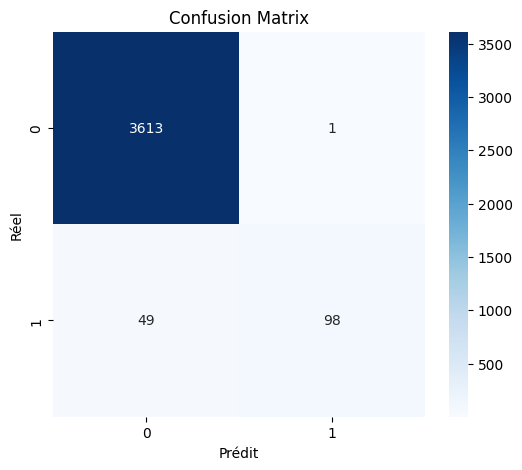

In [ ]:
# =========================================================
# VISUALISATION
# =========================================================

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues"
)

plt.xlabel("Prédit")
plt.ylabel("Réel")

plt.title("Confusion Matrix")

plt.show()

In [ ]:
TN, FP, FN, TP = cm.ravel()

print("TN :", TN)
print("FP :", FP)
print("FN :", FN)
print("TP :", TP)

TN : 3613
FP : 1
FN : 49
TP : 98


In [ ]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'mae', 'val_accuracy', 'val_loss', 'val_mae'])

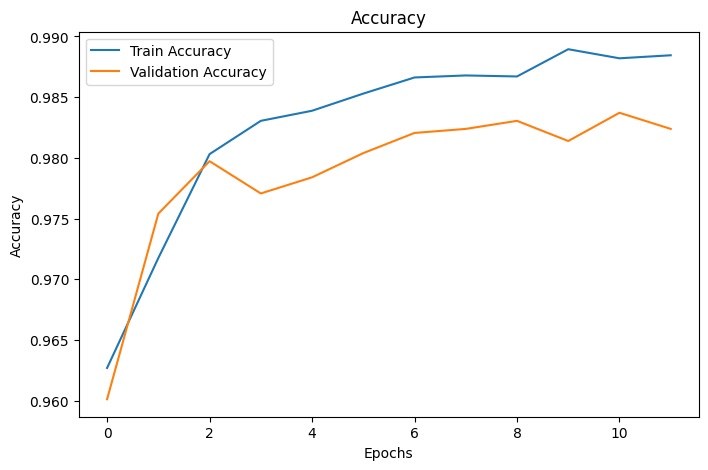

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["accuracy"],
    label="Train Accuracy"
)

plt.plot(
    history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")

plt.legend()

plt.show()

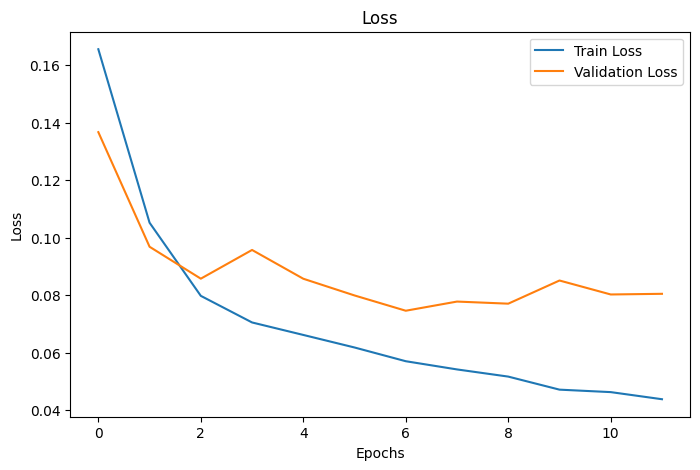

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(
    history.history["loss"],
    label="Train Loss"
)

plt.plot(
    history.history["val_loss"],
    label="Validation Loss"
)

plt.title("Loss")

plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()

plt.show()